Algoritmos Genéticos y Optimización Heurística - UTN-FRT
# **Trabajo Práctico N°3**
## **Tema**: Operadores Genéticos

Integrantes: Arnedo Emmanuel - 52304
Arnedo Mateo - 53813 
Zelarayan Camila - 57261

## Ejercicio 1
Implemente el operador de selección con Ruleta con pesos, completando el código dado.

In [21]:
import random
import matplotlib.pyplot as plt

In [ ]:
def sel_ruleta(F, cant_selectos, eps):
    """ Operador de selección por torneos.
    Parametros:
    F: list
        Lista de valores de fitness de cada individuo de la población.
    cant_selectos: int
        Cantidad de individuos a seleccionar.
    eps: float
        Valor de fitness normalizado para el peor individuo.
    S: list
        Lista con las POSICIONES de los individuos seleccionados.
        Por ejemplo, si se tiene una población de 5 individuos, éstos
        están en la posición 0,1,2,3,4 en la población. Si sale selecto el
        primero y el último, se debe devolver un vector [0,4].
    """
    
    # 1) Normalización: el peor individuo queda con fitness = eps (> 0)
    min_f = min(F)
    F_norm = [f - min_f + eps for f in F]
    
    # 2) Probabilidades de selección (pesos de la ruleta)
    sum_f = sum(F_norm)
    prob = [f / sum_f for f in F_norm]
    
    # 3) Un tiro por cada individuo a seleccionar (con reposición)
    S = []
    for _ in range(cant_selectos):  
        r = random.random()             # Punto aleatorio en [0, 1)
        acumulado = 0
        for i, p in enumerate(prob):
            acumulado += p
            if r <= acumulado:          # Primer sector cuyo borde supera a r
                S.append(i)
                break

    return S # Se debe devolver una lista de tamaño "cant_selectos"

In [ ]:
# PRUEBA
F = [0.54, 0.28, 0.16, 0.12]
eps = 0.1
cant_tiros = 5

# Aplicar seleccion
sel = sel_ruleta(F, cant_tiros, eps)
print('Posicion de individuos seleccionados:')
print(sel)

Posicion de individuos seleccionados:
[2, 0, 1, 2, 0]


### Explicación del código
- **Normalización:** `f - min_f + eps` desplaza todos los fitness para que sean positivos. El peor individuo queda con `eps` (pequeño pero distinto de cero), por lo que conserva una chance mínima de salir. Esto permite usar fitness negativos, como en el Ejercicio 2.
- **Probabilidades:** `prob[i] = f_norm[i] / suma`: cada individuo ocupa en la ruleta un sector proporcional a su fitness.
- **Tiros:** cada tiro sortea `r` en [0, 1) y devuelve el primer individuo cuyo borde acumulado es mayor que `r`. La selección es **con reposición**: un individuo puede salir varias veces.
- **Salida:** se devuelven *posiciones* (no individuos) y la lista tiene exactamente `cant_selectos` elementos.

### Conclusión
La ruleta reparte la presión selectiva en proporción al fitness: el mejor individuo sale más seguido, pero los peores conservan alguna chance, lo que ayuda a mantener diversidad. El parámetro `eps` controla qué tan "pareja" es la ruleta: un `eps` grande la acerca a una selección uniforme y uno chico acentúa la ventaja del mejor.

Los operadores de selección son los encargados de aplicar la "presión selectiva", es decir, guiar al algoritmo hacia las mejores soluciones. La selección por ruleta es proporcional y puede sufrir si los valores de fitness son muy similares (todos tendrían casi la misma probabilidad). La selección por torneo es generalmente preferida en la práctica porque es más rápida, no requiere normalizar el fitness (solo compararlo) y permite ajustar la presión selectiva fácilmente modificando el tamaño del torneo (torneos más grandes significan mayor presión para elegir a los mejores).

## Ejercicio 2
Genere un histograma que muestre la probabilidad de ser seleccionado de cada individuo (basado en su fitness), y un histograma con la cantidad de veces que cada individuo es efectivamente seleccionado. Utilice una población con 10 individuos y el operador de seleccion implementado en el punto anterior sobre la función de evaluación f(x,y) = -sum(x^2 + y^2). ¿Qué diferencia hay al seleccionar 10, 100 y 1000 tiros con el operador dado?

In [24]:
def histograma(pop, fitness, p_selectos, eps):
    #estimo probabilidad de cada individuo de ser seleccionado
    min_f = min(fitness)
    f_norm = [fi - min_f + eps for fi in fitness]
    sum_f = sum(f_norm)
    prob = [fi / sum_f for fi in f_norm]

    # Obtener cantidad relativa de soluciones obtenidas
    c = [0] * len(prob)
    for p in p_selectos:
        c[p] = c[p] + 1
    cant = [ci / len(p_selectos) for ci in c]

    # Obtengo el orden en el que voy a graficar
    psort = sorted(range(len(prob)), key=lambda k: prob[k])

    # Mostrar graficas
    plt.figure()
    plt.bar(range(len(prob)), [prob[p] for p in psort])
    plt.title('Probabilidad de cada individuo')
    plt.xlabel('Individuo')
    plt.ylabel('Probabilidad')

    plt.figure()
    plt.bar(range(len(cant)), [cant[p] for p in psort])
    plt.title('Cantidad de veces que fue seleccionado')
    plt.xlabel('Individuo')
    plt.ylabel('Cantidad relativa')

def generar_poblacion(bounds, cant_soluciones):
    pop = []
    for i in range(cant_soluciones):
        s = [random.random() * (b[1] - b[0]) + b[0] for b in bounds]
        pop.append(s)
    return pop

def fitness(S):
    # f(x, y) = -sum(x^2 + y^2): se maximiza, el óptimo está en (0, 0)
    return -sum([xi**2 for xi in S])

Se usa **la misma población** para las tres corridas (10, 100 y 1000 selecciones), de modo que la única diferencia sea la cantidad de tiros.

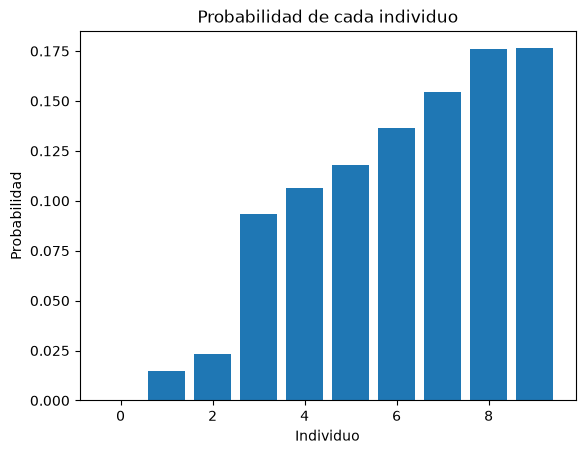

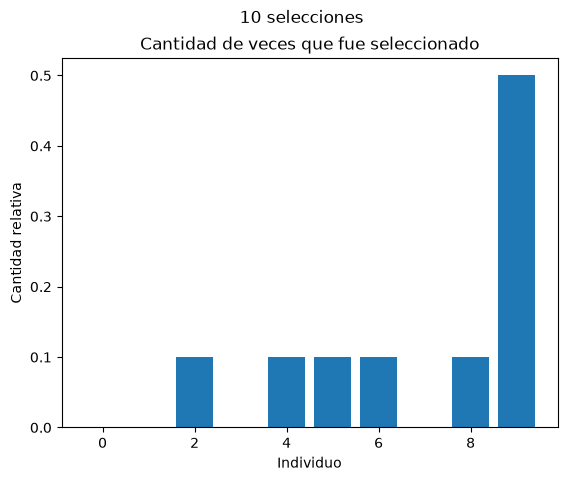

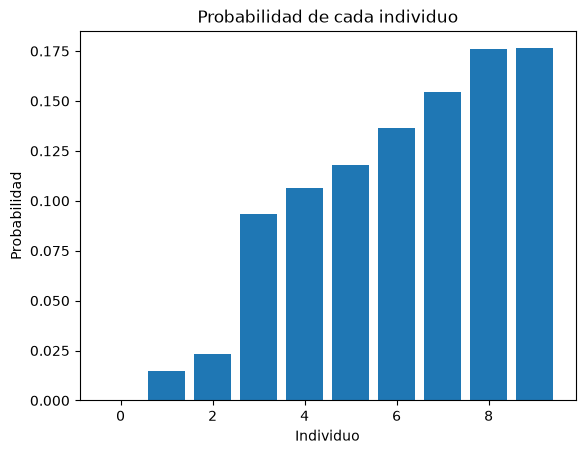

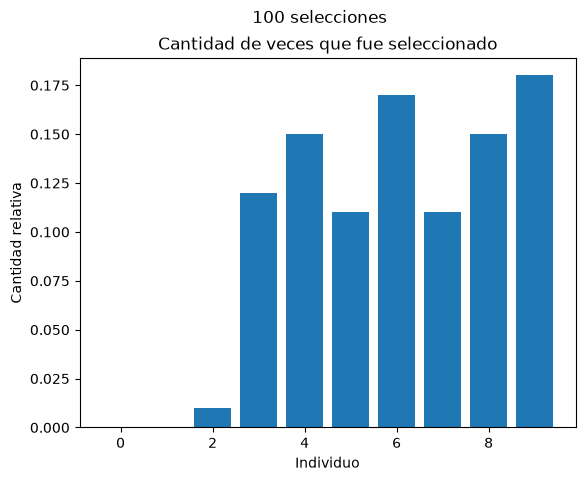

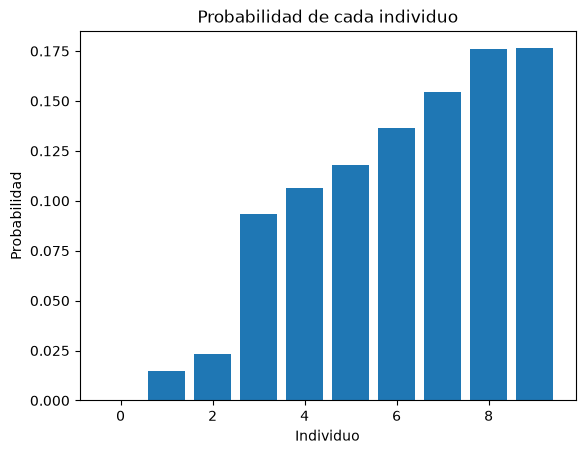

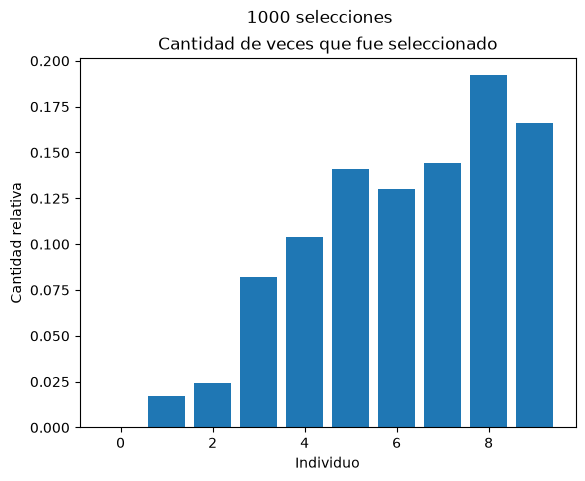

In [ ]:
# PRUEBA
cant_soluciones = 10
eps = 0.1
bounds = [[0, 10], [0, 10]]  # 2 coordenadas

# Generar una poblacion de individuos de prueba
pop = generar_poblacion(bounds, cant_soluciones)

# Evaluar cada individuo
F = [fitness(s) for s in pop]

selecciones = {}
for cant_tiros in (10, 100, 1000):
    # Aplicar seleccion
    sel = sel_ruleta(F, cant_tiros, eps)
    selecciones[cant_tiros] = sel
    # Mostrar histograma
    histograma(pop, F, sel, eps)
    plt.suptitle(f'{cant_tiros} selecciones')
plt.show()

### Tabla comparativa
Se mide qué tan lejos queda la frecuencia observada de la probabilidad teórica (*distancia total*: mitad de la suma de diferencias absolutas) y cuántos individuos nunca fueron elegidos.

In [26]:
min_f = min(F)
f_norm = [fi - min_f + eps for fi in F]
prob = [fi / sum(f_norm) for fi in f_norm]

print(f"{'Selecciones':>12} | {'Nunca elegidos':>14} | {'Dist. total':>11} | {'Dif. máx. por individuo':>23}")
for n, sel in selecciones.items():
    cant = [sel.count(k) / n for k in range(len(F))]
    dist = sum(abs(cant[k] - prob[k]) for k in range(len(F))) / 2
    dmax = max(abs(cant[k] - prob[k]) for k in range(len(F)))
    nunca = sum(1 for x in cant if x == 0)
    print(f"{n:>12} | {nunca:>14} | {dist:>11.3f} | {dmax:>23.3f}")

 Selecciones | Nunca elegidos | Dist. total | Dif. máx. por individuo
          10 |              4 |       0.401 |                   0.324
         100 |              2 |       0.107 |                   0.044
        1000 |              1 |       0.042 |                   0.023


### Explicación del código
- `generar_poblacion` crea 10 individuos de 2 coordenadas uniformes en [0, 10].
- `fitness` devuelve `-(x² + y²)`: problema de maximización donde los individuos cercanos al origen son mejores. Todos los valores son negativos, por eso la normalización con `eps` es necesaria.
- `histograma` calcula la probabilidad teórica (misma normalización que la ruleta) y la compara con la frecuencia relativa observada. Ordena los individuos de menor a mayor probabilidad para que las barras queden crecientes y sea fácil comparar ambos gráficos.

### ¿Qué diferencia hay al seleccionar 10, 100 y 1000 individuos?
- **10 selecciones:** el histograma observado se parece poco al teórico. Hay individuos que salen 2 o 3 veces y otros que no salen nunca, incluso con probabilidad teórica alta. Domina el azar.
- **100 selecciones:** ya se distingue la forma creciente del histograma teórico, pero con ruido visible.
- **1000 selecciones:** la frecuencia observada es casi idéntica a la probabilidad teórica (diferencia por individuo de aprox. 1 punto porcentual).
- El **peor individuo** tiene probabilidad casi nula (`eps` pequeño frente a la suma de fitness normalizados), por lo que normalmente no sale aun con 1000 tiros.

### Conclusión
La ruleta es un operador estocástico: su comportamiento coincide con las probabilidades teóricas solo cuando hay muchos tiros (ley de los grandes números). En un algoritmo genético real, con pocos tiros por generación, hay que esperar mucha varianza: buenos individuos pueden quedar sin selección y malos pueden salir. Por eso existen variantes como la selección universal estocástica (SUS), que reduce esa varianza. Además, la ruleta es sensible a la escala del fitness: `eps` y la normalización controlan la presión selectiva.

## Ejercicio 3
Implemente el operador Uniform crossover, completando el código. Luego apliquelos a los dos individuos dados.

In [ ]:
def xov_uniform(P1, P2):
    """Operador Uniform Crossover para Algoritmos Geneticos.
    Parametros:
    P1: list
        Lista correspondiente a uno de los individuos padres a cruzar.
    P2: list
        Lista correspondiente a uno de los individuos padres a cruzar.
    """
    
    C1 = []
    C2 = []
    # Iteramos sobre cada gen de los padres
    for i in range(len(P1)):
        # Con probabilidad de 0.5 intercambiamos los genes
        if random.random() < 0.5:
            C1.append(P1[i])
            C2.append(P2[i])
        else:
            C1.append(P2[i])
            C2.append(P1[i])

    return C1, C2 # Devolver listas del mismo tamaño que P1 y P2

In [28]:
P1 = [2.1, 9.3, 7.4, 1.8, 5.2]
P2 = [4.2, 1.6, 2.7, 6.4, 5.9]
print("Individuos Padres")
print(P1)
print(P2)

C1, C2 = xov_uniform(P1, P2)
print("Uniform Crossover")
print(C1)
print(C2)

Individuos Padres
[2.1, 9.3, 7.4, 1.8, 5.2]
[4.2, 1.6, 2.7, 6.4, 5.9]
Uniform Crossover
[2.1, 9.3, 2.7, 6.4, 5.2]
[4.2, 1.6, 7.4, 1.8, 5.9]


A diferencia del cruce de un punto o dos puntos (donde se corta el vector y se intercambian bloques enteros), el Uniform Crossover evalúa gen por gen.
En el código propuesto, iteramos por cada posición del vector (gen). Generamos un número aleatorio; si es menor a 0.5 (50% de probabilidad), el Hijo 1 hereda el gen del Padre 1 y el Hijo 2 el del Padre 2. Si es mayor, se invierte la herencia. El resultado son dos descendientes que mezclan el material genético de sus padres de forma totalmente distribuida.
### Explicación del código
- Los hijos empiezan como copias (`.copy()`) de los padres para no modificar las listas originales.
- Por cada posición se sortea un número: si es menor que 0.5, `C1` y `C2` **intercambian** el gen de esa posición; si no, cada hijo conserva el gen de su padre.
- Los hijos son **complementarios**: en cada posición, uno tiene el gen de `P1` y el otro el de `P2`. No se pierde material genético, solo se redistribuye.

### Conclusión
A diferencia del cruce de un punto, el uniform crossover no depende del orden de los genes: cualquier combinación de genes es posible, lo que lo hace muy exploratorio y sin sesgo posicional. Como contrapartida, puede romper bloques de genes que funcionan bien juntos y, en representación real, solo recombina valores existentes sin crear valores nuevos (eso lo aporta la mutación).

## Ejercicio 4
Implemente los siguientes operadores de mutación completando el código dado.
1. Boundary Mutation
2. Step Mutation

In [ ]:
def mut_boundary(P, Bounds):
    """Step Mutation
    Parámetros
    P: list
        Vector correspondiente a un individuo.
    bounds: list
        Matriz que indica los valores maximo y minimo de cada coordenada.
    """
    C = P.copy()
    cut = random.randint(0,len(P)-1)
    C[cut] = bounds[cut][random.randint(0,1)]
    return C

def mut_step(P, Bounds):
    """Step Mutation
    Parámetros
    P: list
        Vector correspondiente a un individuo.
    bounds: list
        Matriz que indica los valores maximo y minimo de cada coordenada.
    """
    
    C = P.copy()
    cut = random.randint(0, len(P)-1)
    
    # Definimos un tamaño de paso (step), por ejemplo un pequeño porcentaje del rango total (ej: 10%)
    rango = bounds[cut][1] - bounds[cut][0]
    step = rango * 0.10 
    
    # Decidimos si sumamos o restamos el paso
    if random.random() < 0.5:
        C[cut] += step
    else:
        C[cut] -= step
        
    # Validamos que el gen mutado no se salga de los límites permitidos [bounds]
    if C[cut] > bounds[cut][1]:
        C[cut] = bounds[cut][1]
    elif C[cut] < bounds[cut][0]:
        C[cut] = bounds[cut][0]

    return C # Devolver lista del mismo tamaño que P

In [30]:
P = [2.1, 9.3, 7.4, 1.8, 5.2]
bounds = [[0,10], [0,10], [0,10], [0,10], [0,10]]

print("Individuo original")
print(P)

C = mut_boundary(P, bounds)
print("Boundary Mutation")
print(C)

C = mut_step(P, bounds)
print("Step Mutation")
print(C)

Individuo original
[2.1, 9.3, 7.4, 1.8, 5.2]
Boundary Mutation
[2.1, 9.3, 7.4, 10, 5.2]
Step Mutation
[2.1, 9.3, 7.4, 2.8, 5.2]


### Explicación del código
La mutación se aplica a un individuo para introducir diversidad genética.   
* Boundary Mutation: Elige una variable al azar (cut) y fuerza su valor al extremo máximo o mínimo permitido en sus límites (bounds).   
* Step Mutation: Modifica el valor de un gen sumando o restando una pequeña cantidad o "paso" (por ejemplo, el 10% del rango de la variable). Dado que se suma o resta un valor, es estrictamente necesario incluir un bloque condicional (if/elif) para verificar que el nuevo valor no exceda los límites máximos y mínimos permitidos por bounds.

### Conclusión:
La mutación es el mecanismo principal para evitar que el algoritmo genético quede atrapado en "óptimos locales".
La Boundary Mutation es agresiva y favorece la exploración radical, lanzando la solución hacia las fronteras del espacio de búsqueda (útil si la solución óptima suele estar en los extremos).
La Step Mutation, por otro lado, actúa como un mecanismo de búsqueda local o sintonía fina (fine-tuning). Realiza pequeños ajustes en las variables, permitiendo que el algoritmo refine una solución que ya es buena para acercarla suavemente al óptimo global.
Son dos mutaciones con roles opuestos. La **boundary** es un salto grande y brusco: útil para explorar los extremos del espacio y escapar de óptimos locales, pero destructiva si se usa sola. La **step** hace un ajuste fino alrededor de la solución actual: útil para explotar zonas prometedoras. En la práctica se combinan, usando la step con más frecuencia y la boundary ocasionalmente. El tamaño de `paso` es un parámetro a calibrar: muy grande se parece a una mutación aleatoria; muy chico hace que la búsqueda avance demasiado lento.